In [40]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier


In [41]:
iris=load_iris()

In [42]:
print(iris)

{'data': array([[5.1, 3.5, 1.4, 0.2],
       [4.9, 3. , 1.4, 0.2],
       [4.7, 3.2, 1.3, 0.2],
       [4.6, 3.1, 1.5, 0.2],
       [5. , 3.6, 1.4, 0.2],
       [5.4, 3.9, 1.7, 0.4],
       [4.6, 3.4, 1.4, 0.3],
       [5. , 3.4, 1.5, 0.2],
       [4.4, 2.9, 1.4, 0.2],
       [4.9, 3.1, 1.5, 0.1],
       [5.4, 3.7, 1.5, 0.2],
       [4.8, 3.4, 1.6, 0.2],
       [4.8, 3. , 1.4, 0.1],
       [4.3, 3. , 1.1, 0.1],
       [5.8, 4. , 1.2, 0.2],
       [5.7, 4.4, 1.5, 0.4],
       [5.4, 3.9, 1.3, 0.4],
       [5.1, 3.5, 1.4, 0.3],
       [5.7, 3.8, 1.7, 0.3],
       [5.1, 3.8, 1.5, 0.3],
       [5.4, 3.4, 1.7, 0.2],
       [5.1, 3.7, 1.5, 0.4],
       [4.6, 3.6, 1. , 0.2],
       [5.1, 3.3, 1.7, 0.5],
       [4.8, 3.4, 1.9, 0.2],
       [5. , 3. , 1.6, 0.2],
       [5. , 3.4, 1.6, 0.4],
       [5.2, 3.5, 1.5, 0.2],
       [5.2, 3.4, 1.4, 0.2],
       [4.7, 3.2, 1.6, 0.2],
       [4.8, 3.1, 1.6, 0.2],
       [5.4, 3.4, 1.5, 0.4],
       [5.2, 4.1, 1.5, 0.1],
       [5.5, 4.2, 1.4, 0.2],
     

In [43]:
df=pd.DataFrame(iris.data,columns=iris.feature_names)
df['Target']=iris.target
print(df.head())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   Target  
0       0  
1       0  
2       0  
3       0  
4       0  


In [44]:
# EDA - Exploratory data analysis ( Analyze the data )
print("Shape of dataset:",df.shape)

Shape of dataset: (150, 5)


In [45]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   Target             150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB


In [46]:
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


In [47]:
print(df.isnull().sum())

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
Target               0
dtype: int64


In [48]:
print(df['Target'].value_counts())
# We have to classify in categorical data not 0,1,2 index

Target
0    50
1    50
2    50
Name: count, dtype: int64


In [49]:
df['Species']=df['Target'].map({0:'setosa',1:'versicolor',2:'virginica'})
print(df.head())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   Target Species  
0       0  setosa  
1       0  setosa  
2       0  setosa  
3       0  setosa  
4       0  setosa  


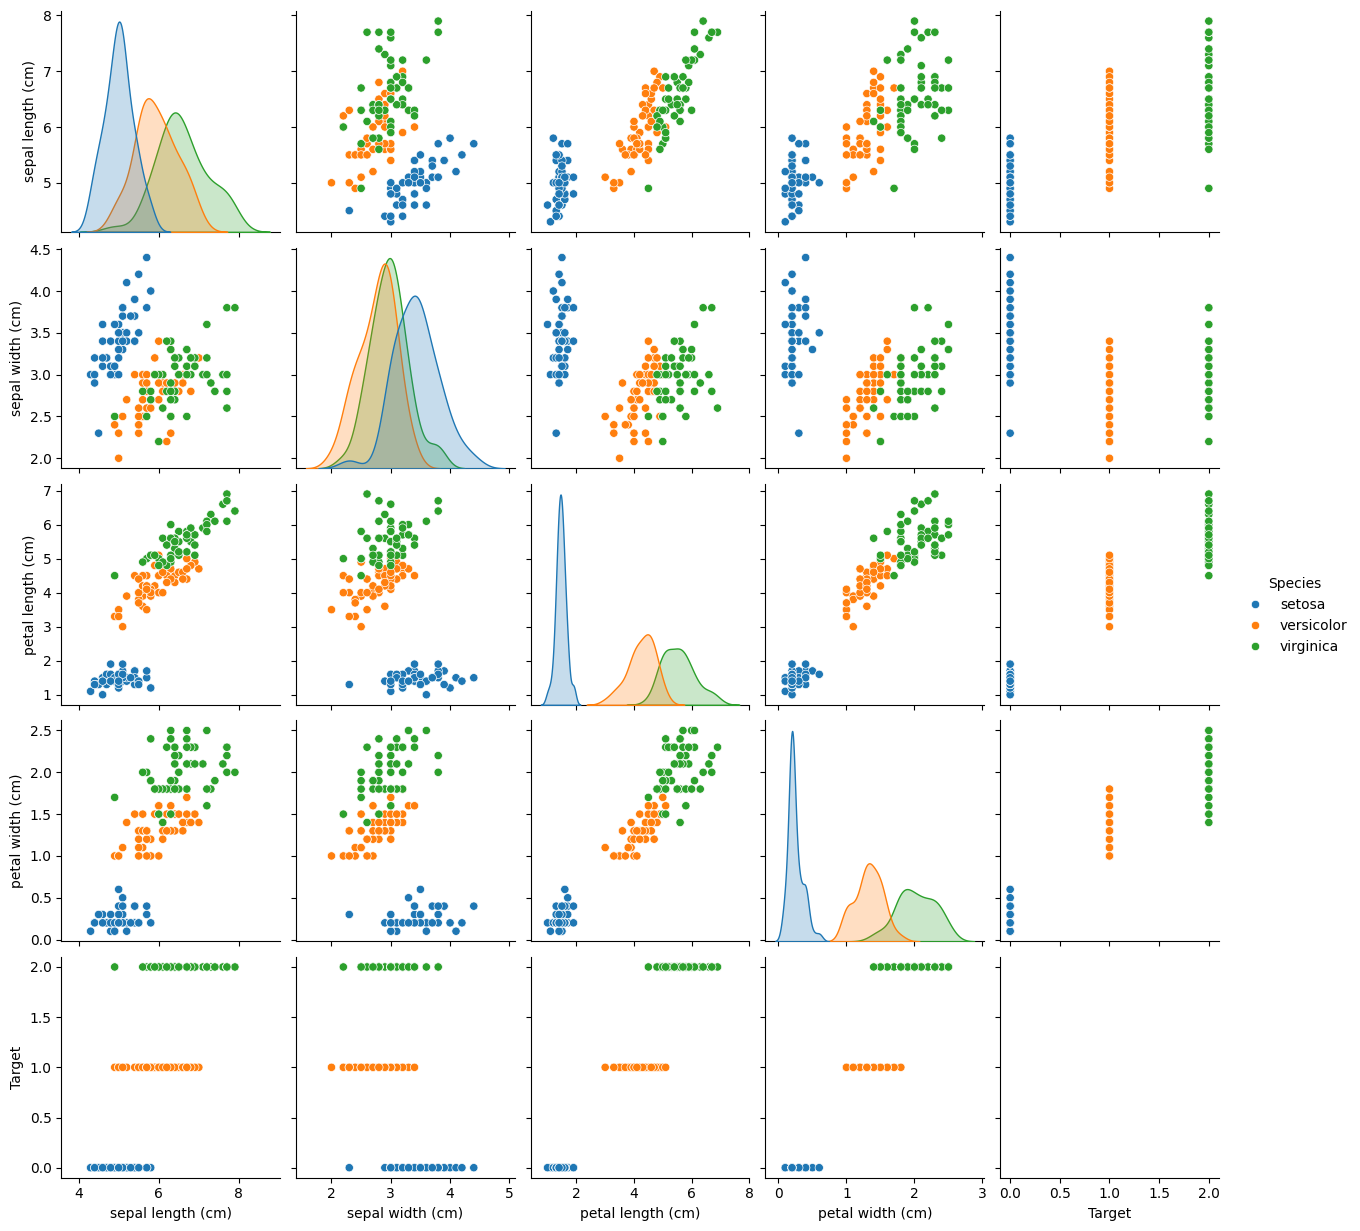

In [50]:
# Pairplot- shows relationship between features
sns.pairplot(df,hue='Species')
plt.show()

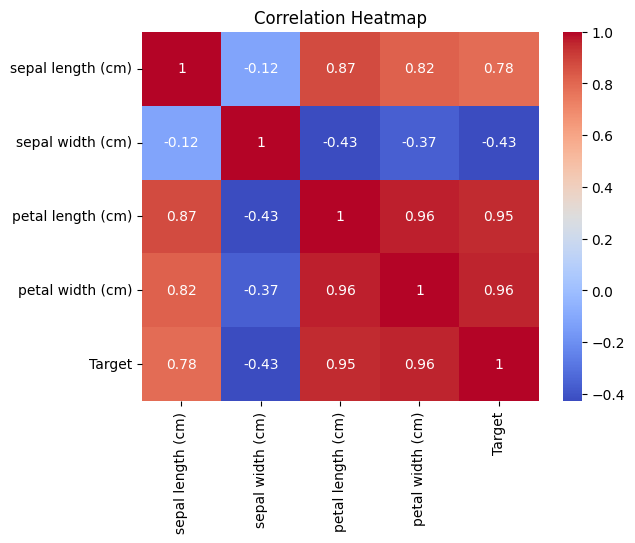

In [51]:
# Correlation - how numerical features are related

#remove text based columns bcs corr. used in numerical only
correlation=df.drop(columns=['Species']).corr()

# To show the relation intensity use heat map
sns.heatmap(correlation,annot=True,cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()


In [52]:
# Preprocessing
# 1.divide fe into input-output
x=df[iris.feature_names]
y=df['Target']
print("Inpt features:")
print(x.head())
print("\nTarget :")
print(y.head())

Inpt features:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2

Target :
0    0
1    0
2    0
3    0
4    0
Name: Target, dtype: int64


In [53]:
# 2.Splitting the data into training and testing (80-20 %)
# x_train-input features for training
# x_test-input features for testing
# y_train-correct ans. for training
# y_test-correct ans. for testing
# stratify= to maintain the propotion in y (IN y= 3 flowers types with 50 records in each )
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42,stratify=y)
print("Training features:",x_train.shape)
print("Testing feaatures:",x_test.shape)
print("Training target:",y_train.shape)
print("Testing target:",y_test.shape)


Training features: (120, 4)
Testing feaatures: (30, 4)
Training target: (120,)
Testing target: (30,)


In [54]:
# 3.Standard scaler for feature scalling
# fit_transform , fit= mean and SD calculate and standardize
scaler=StandardScaler()
x_train_scaled=scaler.fit_transform(x_train)
x_test_scaled=scaler.transform(x_test)

print("Orignal training data:")
print(x_train.head())
print("\nScaled training data:")
print(x_train_scaled[:5])# nested list

Orignal training data:
     sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
8                  4.4               2.9                1.4               0.2
106                4.9               2.5                4.5               1.7
76                 6.8               2.8                4.8               1.4
9                  4.9               3.1                1.5               0.1
89                 5.5               2.5                4.0               1.3

Scaled training data:
[[-1.72156775 -0.33210111 -1.34572231 -1.32327558]
 [-1.12449223 -1.22765467  0.41450518  0.6517626 ]
 [ 1.14439475 -0.5559895   0.58484978  0.25675496]
 [-1.12449223  0.11567567 -1.28894078 -1.45494479]
 [-0.40800161 -1.22765467  0.13059752  0.12508575]]


In [55]:
print("Training data shape:",x_train_scaled.shape)
print("Testing data shape:",x_test_scaled.shape)
print("\nMean of scaled training data:")
print(x_train_scaled.mean(axis=0))
print("\nStandard deviation of scaled training data:")
print(x_train_scaled.std(axis=0))

Training data shape: (120, 4)
Testing data shape: (30, 4)

Mean of scaled training data:
[-1.20829273e-15 -2.03679666e-15  4.99600361e-16  1.67458640e-15]

Standard deviation of scaled training data:
[1. 1. 1. 1.]


In [56]:
# Logistic regression
log_model=LogisticRegression(max_iter=200) # Our Model

# Train the model
log_model.fit(x_train_scaled,y_train)


LogisticRegression(max_iter=200)

In [57]:
y_pred_log=log_model.predict(x_test_scaled)
print("Predicted values :")
print(y_pred_log)

Predicted values :
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 1 2 2 1 0 2 0]


In [58]:
comparison=pd.DataFrame({'Actual values':y_test.values,'Predicted values':y_pred_log})
print(comparison.head())

   Actual values  Predicted values
0              0                 0
1              2                 2
2              1                 1
3              1                 1
4              0                 0


In [59]:
# 2nd Classification model - Decision Tree
dt_model=DecisionTreeClassifier(random_state=42)

# Train model
dt_model.fit(x_train_scaled,y_train)

# make prediction
y_pred_dt=dt_model.predict(x_test_scaled)

print("Predicted values:")
print(y_pred_dt)



Predicted values:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 1 2 2 1 0 2 0]


In [60]:
# Compare actual and predicted values
comparison_dt=pd.DataFrame({'Actual values':y_test.values,'Predicted values':y_pred_dt})
print(comparison_dt.head())

   Actual values  Predicted values
0              0                 0
1              2                 2
2              1                 1
3              1                 1
4              0                 0


In [61]:
# Model evaluation
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,classification_report,confusion_matrix

#Evaluation for Logistic model
print("LOGISTIC REGRESSION RESULTS")
print("Accuracy:",accuracy_score(y_test,y_pred_log))
print("Precision:",precision_score(y_test,y_pred_log,average='weighted'))
print("Recall:",recall_score(y_test,y_pred_log,average='weighted'))
print("F1 score:",f1_score(y_test,y_pred_log,average='weighted'))


LOGISTIC REGRESSION RESULTS
Accuracy: 0.9333333333333333
Precision: 0.9333333333333333
Recall: 0.9333333333333333
F1 score: 0.9333333333333333


In [62]:
#Evaluation of decision tree model
print("DECISION TREE RESULTS")
print("Accuracy:",accuracy_score(y_test,y_pred_dt))
print("Precision:",precision_score(y_test,y_pred_dt,average='weighted'))
print("Recall:",recall_score(y_test,y_pred_dt,average='weighted'))
print("F1 score:",f1_score(y_test,y_pred_dt,average='weighted'))

DECISION TREE RESULTS
Accuracy: 0.9333333333333333
Precision: 0.9333333333333333
Recall: 0.9333333333333333
F1 score: 0.9333333333333333


In [63]:
#classification reports

print("Logistics Regression Classification Report:")
print(classification_report(y_test,y_pred_log))

print("\nDecision Tree Classification Report:")
print(classification_report(y_test,y_pred_dt))

Logistics Regression Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       0.90      0.90      0.90        10
           2       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


Decision Tree Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       0.90      0.90      0.90        10
           2       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



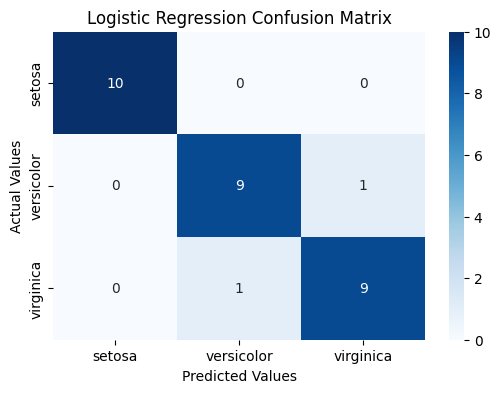

In [64]:
#Cofusion matrix

cm_log = confusion_matrix(y_test, y_pred_log)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_log,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.title("Logistic Regression Confusion Matrix")

plt.show()


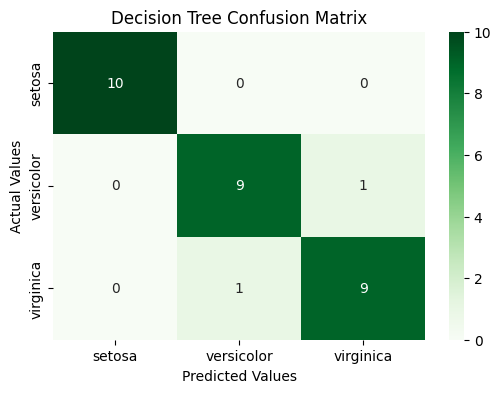

In [65]:
# Confusion matrix for Decision tree

cm_dt = confusion_matrix(y_test, y_pred_dt)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_dt,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.title("Decision Tree Confusion Matrix")

plt.show()

In [66]:
# Decision Boundary Visualization

# preapare 2 features
X_2d = df[['petal length (cm)', 'petal width (cm)']]

y_2d = df['Target']

# split and scale features
X_train_2d, X_test_2d, y_train_2d, y_test_2d = train_test_split(
    X_2d,
    y_2d,
    test_size=0.2,
    random_state=42,
    stratify=y_2d
)
scaler_2d = StandardScaler()
X_train_2d_scaled = scaler_2d.fit_transform(X_train_2d)
X_test_2d_scaled = scaler_2d.transform(X_test_2d)

# Train 2d modeles
log_model_2d = LogisticRegression(max_iter=200)
log_model_2d.fit(X_train_2d_scaled, y_train_2d)
dt_model_2d = DecisionTreeClassifier(random_state=42)
dt_model_2d.fit(X_train_2d_scaled, y_train_2d)

#Function for decision boundaries
def plot_decision_boundary(model, X, y, title):

    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1

    xx, yy = np.meshgrid(
        np.arange(x_min, x_max, 0.02),
        np.arange(y_min, y_max, 0.02)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]
    Z = model.predict(grid)
    Z = Z.reshape(xx.shape)
    plt.figure(figsize=(8, 5))
    plt.contourf(xx, yy, Z, alpha=0.3, cmap='viridis')
    plt.scatter(
        X[:, 0],
        X[:, 1],
        c=y,
        edgecolors='black',
        cmap='viridis'
    )
    plt.xlabel("Petal Length (Standardized)")
    plt.ylabel("Petal Width (Standardized)")
    plt.title(title)
    plt.show()


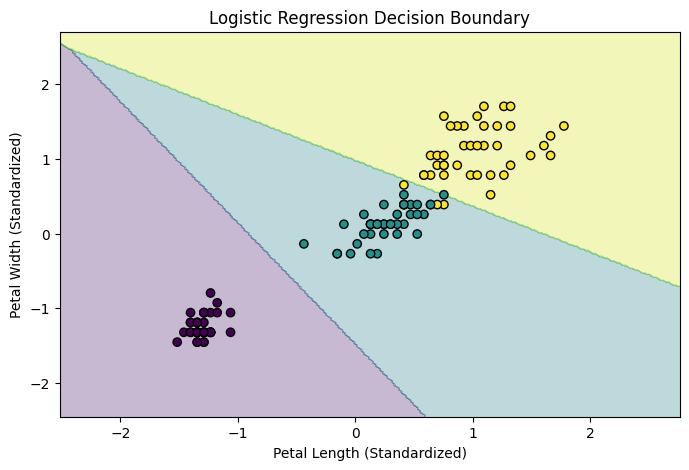

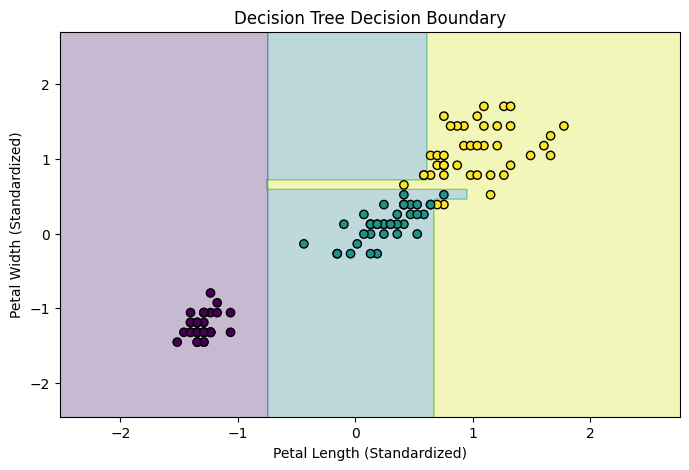

In [67]:
# Plot the logistic decision boundary
plot_decision_boundary(
    log_model_2d,
    X_train_2d_scaled,
    y_train_2d,
    "Logistic Regression Decision Boundary"
)

#plot decision tree decision boundary
plot_decision_boundary(
    dt_model_2d,
    X_train_2d_scaled,
    y_train_2d,
    "Decision Tree Decision Boundary"
)